<a href="https://colab.research.google.com/github/rania-elfadili/python-IA/blob/main/TP4_RANIAELFADILI_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opencv-python matplotlib numpy

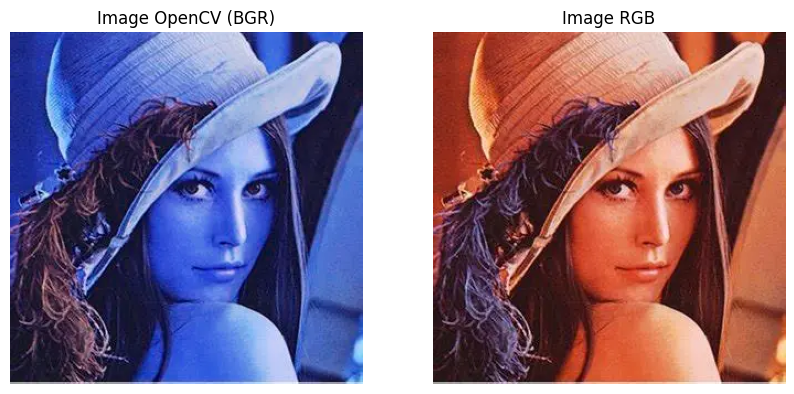

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Chargement de l'image avec OpenCV
image1 = cv2.imread('lena.webp')

# Conversion de l'image de BGR vers RGB cela permet un affichage correct avec matplotlib
image2 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)

# Création d'une figure de taille 10,10 pour bien voir les images
plt.figure(figsize=(10,10))

# Affichage de la première image
plt.subplot(1,2,1)
plt.imshow(image1)
plt.title("Image OpenCV (BGR)")
plt.axis('off')  # on enlève les axes pour une meilleure visualisation

# Affichage de la deuxième image
plt.subplot(1,2,2)
plt.imshow(image2)
plt.title("Image RGB")
plt.axis('off')

# Affichage final des deux images
plt.show()

Shape: (320, 320, 3)
Type: uint8
Shape: (320, 320, 3)
Type: uint8


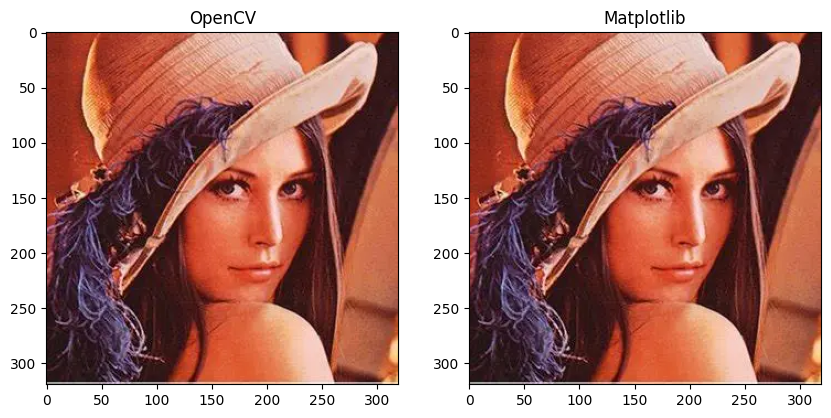

In [ ]:
# importations de biblio important
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
# on charge l'image lena avec opencv
img_cv = cv2.imread('lena.webp')
# de meme on charge l'image avec matplot
img_mat = mpimg.imread('lena.webp')
# on affiche les métadonnées pour la version opencv pour voir shape et dtype
print("Shape:", img_cv.shape)  # (hauteur, largeur, canaux)
print("Type:", img_cv.dtype) # il s'affiche uint8 valeur par defaut
# de meme pour matplot
print("Shape:", img_mat.shape)
print("Type:", img_mat.dtype)  # float32 (si normalisé) ou uint8

# OpenCV utilise le type uint8 avec des valeurs de pixels entre 0;255
# tandis que Matplotlib utilise souvent float32 avec des valeurs normalisées entre 0;1

# on convertie l'immage opencv en RGB
plt.figure(figsize=(10,5))
img_cv_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
plt.subplot(1,2,1)
plt.imshow(img_cv_rgb)
plt.title("OpenCV")
# de meme pour matplot
plt.subplot(1,2,2)
plt.imshow(img_mat)
plt.title("Matplotlib")
# sauvegarde
plt.savefig("comparaison_chargement.png")
plt.show()

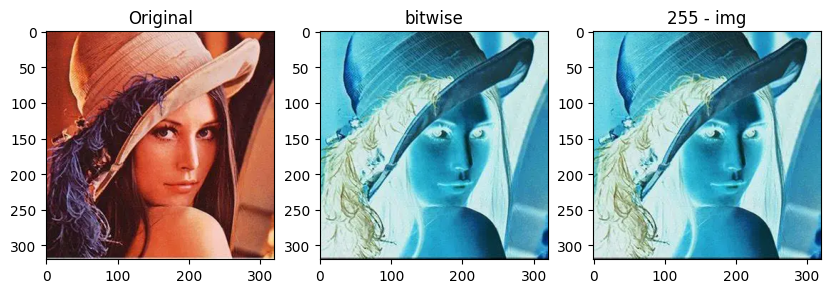

In [ ]:
# charger l'image avec opencv
img = cv2.imread('lena.webp')
# on inverse les couleurs avec "bitwise_not"
img_inv1 = cv2.bitwise_not(img)
# on inverse par la 2 methode 255-I(x,y)
img_inv2 = 255 - img

# afficher l'image originale
plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
# afficher l'image inversé avec bitwise_not
plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(img_inv1, cv2.COLOR_BGR2RGB))
plt.title("bitwise")
# affihcer l'image inversé avec 255-I(x,y)
plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(img_inv2, cv2.COLOR_BGR2RGB))
plt.title("255 - img")
# sauvegarder avec savefig
plt.savefig("inversion_opencv.png")
plt.show()

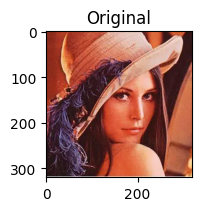

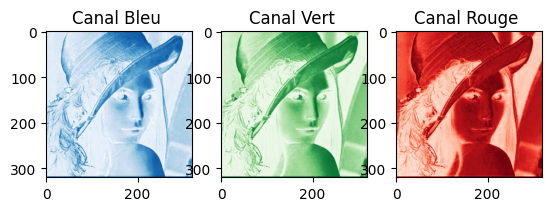

In [ ]:
# chargement de l'image avec opencv
img = cv2.imread('lena.webp')
# On essaye de séparer les canaux pour traiter et visualiser chaque couleur séparément avec split
B, G, R = cv2.split(img)

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.show()
# on affiche les canaux avec des couleurs approprié
plt.subplot(1, 3, 1)
plt.imshow(B, cmap='Blues')
plt.title('Canal Bleu ')

plt.subplot(1, 3, 2)
plt.imshow(G, cmap='Greens')
plt.title('Canal Vert ')

plt.subplot(1, 3, 3)
plt.imshow(R, cmap='Reds')
plt.title('Canal Rouge ')
# sauvegarde d'image
plt.savefig("comparaison_chargement.png")
plt.show()


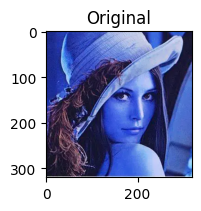

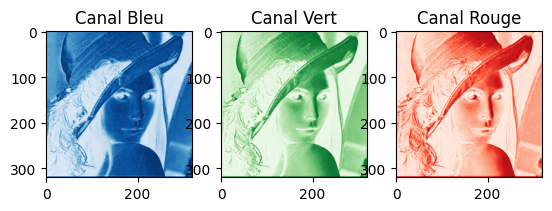

In [ ]:
# chargement de l'image avec matplotlib
img = mpimg.imread('lena.webp')   # mpimg permet de lire l'image directement en format RGB

# Séparation des trois canaux de couleur
B, G, R = cv2.split(img)   #  on suppose un format compatible avec cv2

# Affichage de l'image originale
plt.subplot(1,3,1)

# Conversion BGR en RGB pour un affichage correct avec matplotlib
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.show()


# On affiche chaque canal séparément pour voir l'intensité de chaque couleur

plt.subplot(1, 3, 1)
plt.imshow(B, cmap='Blues')  # canal bleu avec colormap bleue
plt.title('Canal Bleu')

plt.subplot(1, 3, 2)
plt.imshow(G, cmap='Greens')  # canal vert avec colormap verte
plt.title('Canal Vert')

plt.subplot(1, 3, 3)
plt.imshow(R, cmap='Reds')  # canal rouge avec colormap rouge
plt.title('Canal Rouge')


# On sauvegarde la figure
plt.savefig("comparaison_chargement.png")

# Affichage final de toutes les figures
plt.show()

Image chargée avec succès : (320, 320, 3)


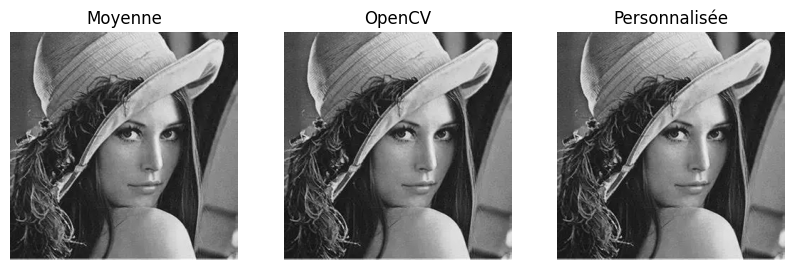

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# On commence par charger l'image avec opencv qui lit les images en format BGR et non RGB
img = cv2.imread('lena.webp')

# Méthode 1  Conversion en gris par moyenne ici on calcule la moyenne des 3 canaux bleu , vert et rouge
# axis=2 signifie qu'on travaille sur les canaux de couleur
img_gray_mean = np.mean(img, axis=2)

# Méthode 2  Conversion avec opencv qui utilise une formule pondérée qui correspond mieux à la vision humaine
# on se base sur que le vert est plus important que le rouge, et le rouge plus que le bleu
img_gray_cv = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Méthode 3  Fonction personnalisée on essaye de créer notre propre fonction pour convertir une image en niveaux de gris en utilisant une formule pondérée classique
def rgbtogray(image):
    # Séparation des canaux
    B = image[:, :, 0] # bleu
    G = image[:, :, 1] # green
    R = image[:, :, 2] # rouge

    # Application de la formule pondérée et cette formule donne un résultat proche de celui d’OpenCV
    gray = 0.299 * R + 0.587 * G + 0.114 * B
    return gray

# Application de la fonction personnalisée
img_gray_custom = rgbtogray(img)


# Affichage des résultats
# On crée une figure pour comparer les trois méthodes
plt.figure(figsize=(10,5))

# Image en niveaux de gris avec la moyenne
plt.subplot(1,3,1)
plt.imshow(img_gray_mean, cmap='gray')
plt.title('Moyenne')
plt.axis('off')  # enlever les axes pour une meilleure visualisation


# Image avec OpenCV
plt.subplot(1,3,2)
plt.imshow(img_gray_cv, cmap='gray')
plt.title('OpenCV')
plt.axis('off')


# Image avec la méthode personnalisée
plt.subplot(1,3,3)
plt.imshow(img_gray_custom, cmap='gray')
plt.title('Personnalisée')
plt.axis('off')


# Sauvegarde de la figure
plt.savefig('comparaison_gris.png')

# Affichage à l'écran
plt.show()

# La méthode par moyenne donne une image moins réaliste
# mais on remarque pour les méthodes pondérées (OpenCV et personnalisée) offrent un meilleur résultat
# Donc la conversion pondérée est la plus fiable